<a href="https://colab.research.google.com/github/eviemcmahan/walmart-hurricane-project/blob/main/notebooks/scratch/2026-10-23%20%E2%80%94%20Midterm%20Checkpoint%20%E2%80%94%20Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Checkpoint

**Lab — 2026-10-23 · Fall 2026**  

---

## Lab 09 — Midterm checkpoint, week 1 of 3

**What you submit: the link to your team's main repo. Only that.** One submission per team. Do not upload separate files.

Put this notebook in the repo (the `notebooks/` folder is fine) and push it, so everything we check is in one place.

**You do not have to fill this all out.** It is a checkpoint, not a finished project. Skip any section you have not started and write "not started" next to it. What we must see is:

1. **Your charter**, committed to the repo
2. **Any progress** you have made, with code that ran and output you can point at

Start with the team setup, then work down the same eight things we listed at Monday's kickoff, as far as you have gotten. This is graded on evidence, not on intentions.

The purpose is to catch a stalled team while there is still time to unstall it. If something is not working, say so here plainly. A checkpoint that honestly reports "the API join is not working and here is the error" is worth more than one that claims progress that does not exist, and it gets you help on Monday.

### Team setup

This part is required. Fill it in once for the whole team.

You need:

- Your team name, and every member with a GitHub handle (2 to 4 people)
- A link to your team's **main repo**. This is the one link you submit.
- A link to `CHARTER.md` in that repo, the page on GitHub, not a file on someone's laptop

Nice to have, and also in your charter: this week's notebook owner, your meeting time, and the five worst problems in the data from the profile you ran on Monday. Be specific: "`unit_price` is stored as text and some values start with `$`" beats "prices are messy."

In [16]:
team_setup = {
    'team_name': 'HEJ',
    'members': [
        {'name': 'Evie McMahan', 'github': 'eviemcmahan'},
        {'name': 'Honor Dold', 'github': 'honordold'},
        {'name': 'Julia McPhillips', 'github': 'juliamcphillips'},
    ],
    'repo_url': 'https://github.com/eviemcmahan/walmart-hurricane-project',                           # https://github.com/...
    'charter_url': 'https://github.com/eviemcmahan/walmart-hurricane-project/blob/main/CHARTER.md',                        # link to CHARTER.md in the repo
    'notebook_owner_this_week': 'Evie McMahan',
    'meeting_time': 'Wednesday, 10 AM',
    'five_worst_problems': [
        'SKUs and names are not consistent for products (Pop-Tarts has 4 SKUs and 6 name spellings)',
        'category has 37 distinct spellings, and after normalizing that only reduces it to 18',
        'timestamp is missing in 886 rows (3.5%)',
        'store_id has 60 distinct values for 12 actual stores',
        'unit_price is a string datatype, with a $ in 3,029 rows',
    ],
}

def check_team(t, quiet=False):
    def real(v):
        return isinstance(v, str) and v.strip() != '' and not v.startswith('TODO')
    required = {
        'team name': real(t['team_name']),
        '2 to 4 members, each with a name and GitHub handle':
            2 <= len(t['members']) <= 4 and all(real(m['name']) and real(m['github']) for m in t['members']),
        'main repo link': real(t['repo_url']) and t['repo_url'].startswith('https://github.com/'),
        'charter link points at CHARTER.md': real(t['charter_url']) and t['charter_url'].endswith('CHARTER.md'),
    }
    nice = {
        'notebook owner': real(t['notebook_owner_this_week']),
        'meeting time': real(t['meeting_time']),
        'five specific problems': len(t['five_worst_problems']) >= 5 and all(real(p) for p in t['five_worst_problems']),
    }
    if not quiet:
        print('REQUIRED')
        for label, good in required.items():
            print('  PASS' if good else '  FAIL', '-', label)
        print('NICE TO HAVE')
        for label, good in nice.items():
            print('  done' if good else '  not yet', '-', label)
        print()
        print('team setup complete:', all(required.values()))
    return all(required.values())

check_team(team_setup)

REQUIRED
  PASS - team name
  PASS - 2 to 4 members, each with a name and GitHub handle
  PASS - main repo link
  PASS - charter link points at CHARTER.md
NICE TO HAVE
  done - notebook owner
  done - meeting time
  done - five specific problems

team setup complete: True


True

Now show that the charter is actually committed. This is required. Run the next cell and leave its output in the notebook. Point `REPO_PATH` at your local clone of the team repo. If it prints a line like `a1b2c3d Add team charter`, you are done. If it prints "no commits found," the charter is not in the repo yet, so commit it and push before you submit.

In [17]:
!git clone https://github.com/eviemcmahan/walmart-hurricane-project

fatal: destination path 'walmart-hurricane-project' already exists and is not an empty directory.


In [18]:
import subprocess

REPO_PATH = '/content/walmart-hurricane-project'

result = subprocess.run(['git', '-C', REPO_PATH, 'log', '--oneline', '--', 'CHARTER.md'],
                        capture_output=True, text=True)
print(result.stdout.strip() or 'no commits found for CHARTER.md')

303a5c9 Update CHARTER.md
2a2e5d9 Update CHARTER.md
48d03ba Create CHARTER.md


### 1 — Your cleaning pipeline as functions

**TODO:** paste the cleaning code you have written so far. It should be functions, not loose cells, and it should cover at minimum: duplicates, `unit_price` to numeric (it comes in as text, some with a `$`), the negative `quantity` values with your decision applied, `timestamp` parsed, and `store_id` cleaned up so it will join to the store file.

Print the row count before and after. We want to see how many rows your decisions removed.

In [19]:
# Trim inconsistent spacing

def trim_text(df, name):
    """Trim and collapse spaces in every string columns; blank strings become missing."""
    out = df.copy()
    text_cols = [c for c in out.columns if not pd.api.types.is_numeric_dtype(out[c])]
    changed = {}
    for c in text_cols: # Go through the cleaning process
        s = out[c]
        cleaned = s.str.strip().str.replace(r'\s+', ' ', regex=True).replace('', np.nan)
        changed[c] = int((s.fillna('') != cleaned.fillna('')).sum())
        out[c] = cleaned
    fixed = {k: v for k, v in changed.items() if v}
    log(f'{name}: trim spaces', ', '.join(text_cols), # Log the decision
        f'trimmed/collapsed spaces, blanks set to missing; values changed: {fixed}',
        len(df), len(out))
    return out

# Fill missing values

def fill_missing(tables):
    out = dict(tables)

    # Catalog: subcategory is a text column, so fill it with a label
    c = out['catalog'].copy()
    n = int(c['subcategory'].isna().sum())
    c['subcategory'] = c['subcategory'].fillna('unknown')
    log('catalog: missing values', 'subcategory', f'filled {n} missing values with "unknown"', len(c), len(c))
    log('catalog: missing values', 'unit_cost', f'left {int(c["unit_cost"].isna().sum())} missing; not used in Q1 to Q5', len(c), len(c))
    out['catalog'] = c

    # Stores: Tallahassee's missing coordinates, city level, from latlong.net
    s = out['stores'].copy()
    mask = s['latitude'].isna() | s['longitude'].isna()
    s.loc[mask, ['latitude', 'longitude']] = [30.455, -84.2533]
    log('stores: missing values', 'latitude, longitude',
        f'filled {int(mask.sum())} store ({s.loc[mask, "city"].tolist()[0]}) with city-level coordinates from latlong.net', len(s), len(s))
    out['stores'] = s

    # Distribution centers: leave Birmingham's shipping cost missing
    d = out['distribution_centers'].copy()
    log('distribution centers: missing values', 'cost_per_shipment',
        f'left {int(d["cost_per_shipment"].isna().sum())} missing (Birmingham); exclude from any cost comparison', len(d), len(d))
    out['distribution_centers'] = d

    # Transactions: timestamp is left missing on purpose; just log the decision
    t = out['transactions']
    log('transactions: missing values', 'timestamp',
        f'kept {int(t["timestamp"].isna().sum())} rows with missing timestamp; excluded only from analysis that needs a date', len(t), len(t))
    return out

# Drop duplicates

def drop_duplicates(df, name): # Drop duplicates function
    n = len(df)
    out = df.drop_duplicates() # Drop the duplicates
    dropped = n - len(out) # Count how many duplicates were dropped
    log(f'{name}: duplicates', 'all columns',
        f'dropped {dropped} exact duplicate rows (kept first copy)', n, len(out)) # Decision log
    print(f'{name}: {n:,} rows to {len(out):,} rows ({dropped} dropped)')
    return out

# DataType formatting

def to_price(s):
    """'$3.38' -> 3.38"""
    out = pd.to_numeric(s.str.replace(r'[$,]', '', regex=True), errors='coerce')
    assert out.notna().all(), 'some prices failed to convert'
    return out

def to_datetime(s):
    """Parse all formats; values that can't be parsed become missing."""
    return pd.to_datetime(s, errors='coerce', format='mixed')

def to_capacity(s):
    """'~750' -> 750"""
    return pd.to_numeric(s.astype(str).str.replace(r'[^0-9.]', '', regex=True))

def fix_types(tables): # Fix all the types
    out = dict(tables)

    t = out['transactions'].copy()
    t['unit_price'] = to_price(t['unit_price']) # Fix unit price in transactions
    t['timestamp'] = to_datetime(t['timestamp']) # Fix timestamp in transactions
    log('transactions: types', 'unit_price, timestamp',
        'unit_price to float (removed $); timestamp parsed to datetime; missing timestamps left missing',
        len(t), len(t))
    out['transactions'] = t

    d = out['distribution_centers'].copy()
    d['surge_capacity_approx'] = d['surge_capacity'].astype(str).str.contains('~')
    d['surge_capacity'] = to_capacity(d['surge_capacity']) # Fix surge capacity in distribution centers
    log('distribution centers: types', 'surge_capacity', 'removed ~, converted to number; approximate value flagged', len(d), len(d))
    out['distribution_centers'] = d
    return out

# Flip negative quantity

def flip_negative_quantity(df, name):
    out = df.copy()
    n_neg = int((out['quantity'] < 0).sum()) # Determine the negative rows first
    out['quantity'] = out['quantity'].abs() # Flip the sign
    log(f'{name}: quantity', 'quantity', # Log the decision
        f'flipped sign on {n_neg} negative rows (likely sign typos)', len(df), len(out))
    print(f'{name}: flipped {n_neg} negative quantities, total units from {df["quantity"].sum():,} to {out["quantity"].sum():,}')
    return out

### 2 — Your decision log

**TODO:** every cleaning decision, what it did, and how many rows it touched. If your teammates disagree with one of these, note the disagreement — that is useful information, not a problem to hide.

In [20]:
# Decision log is in our team notebook

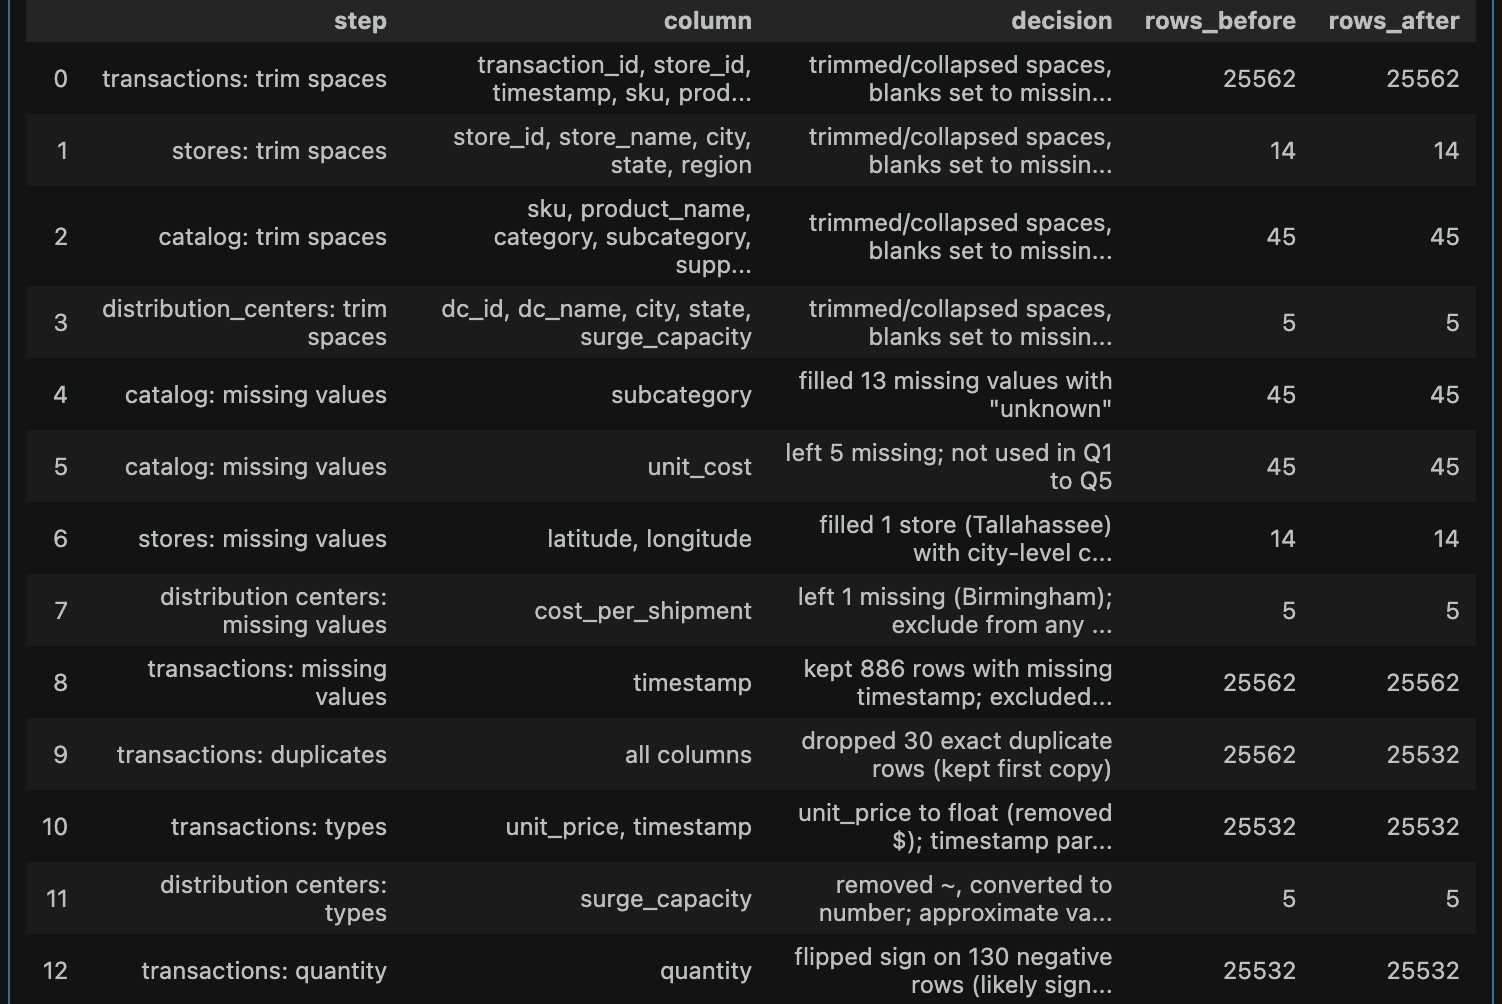

### 3 — SKU consolidation progress

**TODO:** how many distinct SKUs did you start with, how many canonical products do you have now, and what is your largest consolidated group? Show the mapping for at least one product family. Pop-Tarts is a good one to start with.

You do not need this finished — you need it started and defensible.

In [21]:
# Not started

### 4 — One working weather API call

**TODO:** show the call and the parsed DataFrame. It must include the retry logic and a `source` column. Say which timezone the weather timestamps are in and how you will line them up with the sales timestamps. If it is not working, paste the actual error and what you have tried.

In [22]:
# Not started

### 5 — One chart

**TODO:** daily order volume across your date range. It does not need to be presentation quality yet, but it does need labeled axes and a title.

Look at it before you submit. Does the shape make sense? An early chart is the fastest way to catch a cleaning bug — if your daily volume has a day at zero or a day at ten times everything else, that is usually your pipeline, not the hurricane.

In [23]:
# Not started

### 6 — Self-check

Fill in what you have and leave the rest. **The required items are the team setup and the charter.** Everything else is progress we want to see, not a pass or fail. The checks are shape checks; they cannot verify your analysis is right, only that you have gotten far enough to have one.

In [24]:
required = {
    'team_setup_complete': check_team(team_setup, quiet=True),
    'charter_committed': True,
}

progress = {
    'rows_after_cleaning': 25532,        # an integer
    'decisions_logged': 13,           # how many entries in your log
    'canonical_products': None,         # distinct products after consolidation
    'weather_api_rows': None,           # rows returned by your API call
    'notebook_runs_clean': False,       # True after Restart and Run All
}

def is_done(value):
    return not (value is None or value is False
                or (isinstance(value, str) and value.startswith('TODO')))

def check(required, progress):
    print('REQUIRED')
    for label, value in required.items():
        print('  PASS' if is_done(value) else '  FAIL', '-', label, '=', value)
    print('PROGRESS (fill in what you have)')
    for label, value in progress.items():
        print('  done' if is_done(value) else '  not yet', '-', label, '=', value)
    ok = all(is_done(v) for v in required.values())
    print()
    print('required items complete:', ok)
    print('progress items done:', sum(is_done(v) for v in progress.values()), 'of', len(progress))
    return ok

check(required, progress)

REQUIRED
  PASS - team_setup_complete = True
  PASS - charter_committed = True
PROGRESS (fill in what you have)
  done - rows_after_cleaning = 25532
  done - decisions_logged = 13
  not yet - canonical_products = None
  not yet - weather_api_rows = None
  not yet - notebook_runs_clean = False

required items complete: True
progress items done: 2 of 5


True

### 7 — Risk and plan

Two questions, answered concretely.

**a)** What is the single most likely thing to go wrong in the next two weeks? Name a specific technical or team problem, not "running out of time."

**b)** What are you doing about it this week? Name who is doing it and by when.

**Biggest risk:** We think the single most likely thing to go wrong in the next two weeks is not properly communicating about our individual tasks, and making the process more difficult. Since we each have our own responsibilities, such as cleaning the data set or the API part, it is essential we communicate our timelines and summarize what we have done so the group is all on the same page and not confused.

**Plan, with an owner and a date:** We are going to meet as a team on Monday, October 26th after class to confirm our meeting plans for the week (which we have texted about so far). We will also establish deadlines for each of our individual tasks and when summaries need to be sent to the group chat to ensure that we are all confident in what we need to do, and can hold each other accountable for getting it done.

### 8 — Where each question stands

**TODO:** mark each of the five questions. These owners must match the question owners table in your charter. Be honest — this is the section I read first.

| Question | Status | Who owns it |
|---|---|---|
| Q1 demand surge | not started | Julia |
| Q2 SKU consolidation | not started | Evie |
| Q3 weather correlation | not started | Honor |
| Q4 store and geography | not started | Honor |
| Q5 signal or artifact | not started | Evie |

At the end of week 1, "not started" on Q4 and Q5 is expected. "Not started" on all five means come find me on Monday.